# Results from the `cancer_detection` pipeline

Loads the run records written by `python -m cancer_detection run configs/experiments.yaml` (one JSON file per experiment in `results/runs/`). Every number here comes from nested cross-validation on the training set, or from the single held-out test evaluation.

In [1]:
from pathlib import Path

import pandas as pd

from cancer_detection.reporting import load_records

RUNS_DIR = Path.cwd().parent / 'results' / 'runs' if Path.cwd().name == 'notebooks' else Path('results/runs')
records = load_records(RUNS_DIR)
len(records)

46

In [2]:
rows = [{
    'experiment': r['spec']['name'],
    'task': r['spec']['task'],
    'cv_balanced_accuracy': r['nested_cv']['balanced_accuracy']['mean'],
    'cv_balanced_accuracy_sd': r['nested_cv']['balanced_accuracy']['std'],
    'cv_roc_auc': r['nested_cv']['roc_auc']['mean'],
    'test_balanced_accuracy': r['test']['balanced_accuracy'],
    'test_roc_auc': r['test']['roc_auc'],
    'test_sensitivity': r['test']['sensitivity'],
    'test_specificity': r['test']['specificity'],
} for r in records]
results = pd.DataFrame(rows).sort_values(['task', 'cv_balanced_accuracy'], ascending=[True, False])
results.round(3)

,experiment,task,cv_balanced_accuracy,cv_balanced_accuracy_sd,cv_roc_auc,test_balanced_accuracy,test_roc_auc,test_sensitivity,test_specificity
4,hnc_logreg_bins_cw,hnc,0.754,0.067,0.821,0.773,0.869,0.595,0.951
5,hnc_logreg_cw,hnc,0.746,0.039,0.814,0.808,0.886,0.666,0.951
8,hnc_logreg_smote,hnc,0.742,0.044,0.809,0.807,0.890,0.711,0.902
7,hnc_logreg_l1_cw,hnc,0.738,0.064,0.797,0.776,0.839,0.625,0.927
9,hnc_logreg_under,hnc,0.735,0.048,0.798,0.734,0.823,0.712,0.756
10,hnc_rf_bins_cw,hnc,0.732,0.059,0.791,0.760,0.867,0.666,0.854
2,hnc_hgb_cw,hnc,0.717,0.046,0.800,0.777,0.875,0.579,0.976
11,hnc_rf_cw,hnc,0.714,0.052,0.778,0.763,0.871,0.550,0.976
6,hnc_logreg_frag_cw,hnc,0.656,0.076,0.728,0.724,0.783,0.595,0.854
13,hnc_rf_smote,hnc,0.650,0.056,0.742,0.679,0.867,0.359,1.000


Models are chosen by **cross-validated** balanced accuracy only. The test columns are shown for transparency; choosing a model by its test score would make the test set a validation set.

In [3]:
best_by_cv = results.loc[results.groupby('task')['cv_balanced_accuracy'].idxmax()]
best_by_cv[['task', 'experiment', 'cv_balanced_accuracy', 'test_balanced_accuracy', 'test_roc_auc']].round(3)

,task,experiment,cv_balanced_accuracy,test_balanced_accuracy,test_roc_auc
4,hnc,hnc_logreg_bins_cw,0.754,0.773,0.869
24,hne,hne_logreg_smote,0.856,0.877,0.935
14,hne_all,hne_all_logreg_cw,0.746,0.813,0.918
32,hns,hns_dummy,0.500,0.500,0.500
30,hns_all,hns_all_logreg_cw,0.746,0.523,0.648


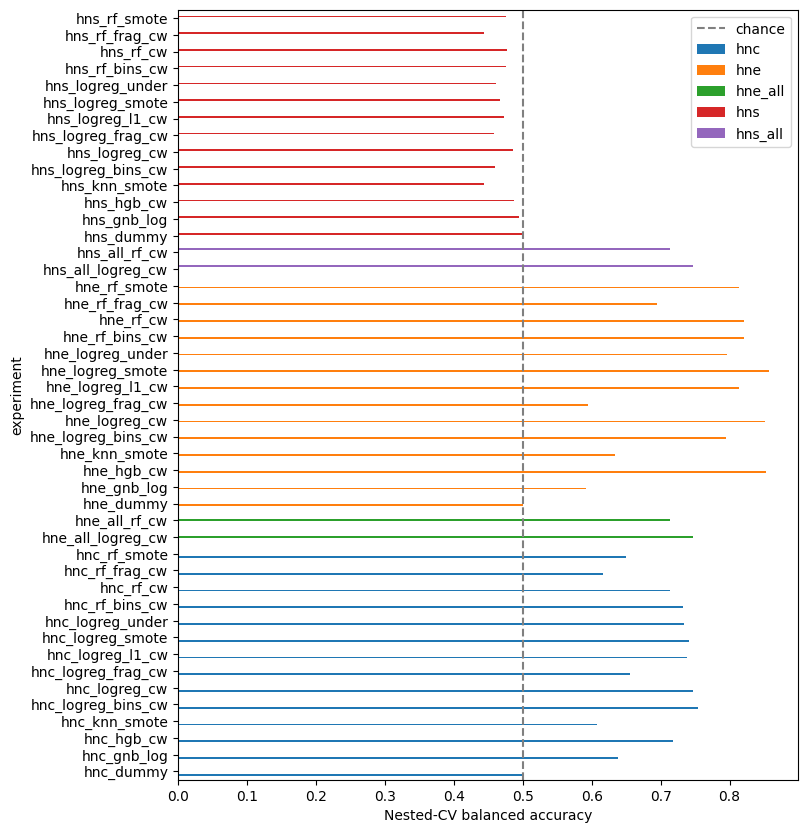

In [4]:
ax = results.pivot(index='experiment', columns='task', values='cv_balanced_accuracy').plot.barh(figsize=(8, 10))
ax.axvline(0.5, color='grey', linestyle='--', label='chance')
ax.set_xlabel('Nested-CV balanced accuracy')
ax.legend()